# Analisi delle razze canine AKC

Tratti caratteriali (TidyTuesday 2022-02-01) uniti ai dati fisici e ai gruppi AKC (`tmfilho/akcdata`).
Tutti i grafici usano sfondo bianco e dettagli in `#1800ad` e vengono salvati nella cartella `grafici/`.

## 0. Setup: librerie, palette e funzioni di stile

In [2]:
# In Colab: umap-learn non è preinstallato
%pip install -q umap-learn

import os, re, unicodedata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap, to_hex, to_rgb
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import warnings
# Avvisi solo informativi di UMAP/tqdm (seed, layout, barra di avanzamento)
warnings.filterwarnings("ignore", message=".*(compatibility_layout|n_jobs value|IProgress not found).*")
import umap

# ---- Palette: sfondo bianco + dettagli #1800ad -------------------------------
PRIMARIO = "#1800ad"

def tinta(frazione):
    """Mescola PRIMARIO con il bianco (1 = colore pieno, 0 = bianco)."""
    p, w = np.array(to_rgb(PRIMARIO)), np.ones(3)
    return to_hex(w + (p - w) * frazione)

CHIARO = tinta(0.45)     # seconda serie / riempimenti
TENUE  = tinta(0.15)     # assi, griglia, elementi di sfondo
NEUTRO = "#9E9E9E"       # polo negativo della heatmap divergente

sns.set_theme(style="white", rc={
    "figure.facecolor": "white", "axes.facecolor": "white", "savefig.facecolor": "white",
    "axes.edgecolor": TENUE, "axes.labelcolor": PRIMARIO, "axes.titlecolor": PRIMARIO,
    "axes.titleweight": "bold", "axes.titlesize": 14, "axes.titlelocation": "left",
    "axes.titlepad": 18, "axes.labelsize": 11, "axes.labelpad": 8,
    "xtick.color": PRIMARIO, "ytick.color": PRIMARIO, "text.color": PRIMARIO,
    "legend.frameon": False, "legend.labelcolor": PRIMARIO,
    "grid.color": TENUE, "grid.linewidth": 0.8,
    "figure.dpi": 110, "savefig.dpi": 300, "savefig.bbox": "tight",
})

CARTELLA_GRAFICI = "grafici"
os.makedirs(CARTELLA_GRAFICI, exist_ok=True)

def stile_assi(ax, griglia="y"):
    """Bordi superiore/destro rimossi, griglia leggera su un solo asse."""
    sns.despine(ax=ax)
    ax.grid(axis=griglia, visible=True)
    ax.grid(axis="x" if griglia == "y" else "y", visible=False)
    ax.set_axisbelow(True)

def salva(fig, nome):
    fig.savefig(os.path.join(CARTELLA_GRAFICI, nome))
    plt.show()

## 1. Caricamento e unione dei dati

I due dataset scrivono i nomi in modo diverso (es. `Retrievers (Labrador)` vs `Labrador Retriever`),
quindi i nomi vengono normalizzati (spazi speciali, accenti, plurali, ordine delle parole) prima dell'unione.

In [5]:
URL_TRATTI = "https://raw.githubusercontent.com/rfordatascience/tidytuesday/master/data/2022/2022-02-01/breed_traits.csv"
URL_FISICI = "https://raw.githubusercontent.com/tmfilho/akcdata/master/data/akc-data-latest.csv"

df = pd.read_csv(URL_TRATTI)
df["Breed"] = df["Breed"].str.replace("\xa0", " ").str.strip()

fisici = pd.read_csv(URL_FISICI).rename(columns={"Unnamed: 0": "Breed"})
fisici[["min_weight", "max_weight"]] = fisici[["min_weight", "max_weight"]].replace(0, np.nan)  # 0 kg = dato mancante
fisici["avg_weight"] = fisici[["min_weight", "max_weight"]].mean(axis=1)
fisici["avg_height"] = fisici[["min_height", "max_height"]].mean(axis=1)

# Plurali irregolari / nomi diversi tra i due dataset
ALIAS = {
    "Poodles": "Poodle (Standard)", "Manchester Terriers": "Manchester Terrier (Standard)",
    "Siberian Huskies": "Siberian Husky", "St. Bernards": "Saint Bernard",
    "Lagotti Romagnoli": "Lagotto Romagnolo", "Keeshonden": "Keeshond",
    "Spinoni Italiani": "Spinone Italiano", "Pulik": "Puli", "Pumik": "Pumi",
    "Kuvaszok": "Kuvasz", "Komondorok": "Komondor", "Cirnechi dell’Etna": "Cirneco dell’Etna",
}

def chiave(nome):
    nome = unicodedata.normalize("NFKD", ALIAS.get(nome, nome)).encode("ascii", "ignore").decode().lower()
    parole = re.sub(r"[^a-z0-9 ]", " ", nome).split()
    parole = [p[:-1] if p.endswith("s") and not p.endswith("ss") and len(p) > 3 else p for p in parole]
    return " ".join(sorted(parole))

df["k"] = df["Breed"].map(chiave)
fisici["k"] = fisici["Breed"].map(chiave)
df = df.merge(fisici[["k", "avg_weight", "avg_height", "group"]], on="k", how="left").drop(columns="k")

TRATTI = df.select_dtypes("number").columns.drop(["avg_weight", "avg_height"]).tolist()

# Plott Hounds ha tutti i tratti a 0 (fuori dalla scala 1-5): escluso dalle analisi
validi = (df[TRATTI] > 0).all(axis=1)
print("Escluse per tratti non validi:", df.loc[~validi, "Breed"].tolist())
df = df[validi].reset_index(drop=True)

df.to_excel("akc_breeds.xlsx", index=False)
print(f"Razze: {len(df)} | con peso: {df['avg_weight'].notna().sum()} | con gruppo: {df['group'].notna().sum()}")
df.head()

Escluse per tratti non validi: ['Plott Hounds']
Razze: 194 | con peso: 192 | con gruppo: 194


,Breed,Affectionate With Family,Good With Young Children,Good With Other Dogs,Shedding Level,Coat Grooming Frequency,Drooling Level,Coat Type,Coat Length,Openness To Strangers,Playfulness Level,Watchdog/Protective Nature,Adaptability Level,Trainability Level,Energy Level,Barking Level,Mental Stimulation Needs,avg_weight,avg_height,group
0,Retrievers (Labrador),5,5,5,4,2,2,Double,Short,5,5,3,5,5,5,3,4,30.617485,58.420,Sporting Group
1,French Bulldogs,5,5,4,3,1,3,Smooth,Short,5,5,3,5,4,3,1,3,12.700586,30.480,Non-Sporting Group
2,German Shepherd Dogs,5,5,3,4,2,2,Double,Medium,3,4,5,5,5,5,3,5,31.751466,60.960,Herding Group
3,Retrievers (Golden),5,5,5,4,2,2,Double,Medium,5,4,3,5,5,3,1,4,29.483504,57.785,Sporting Group
4,Bulldogs,4,3,3,3,3,3,Smooth,Short,4,4,3,3,4,3,2,3,20.411657,36.830,Non-Sporting Group


## 2. Esplorazione

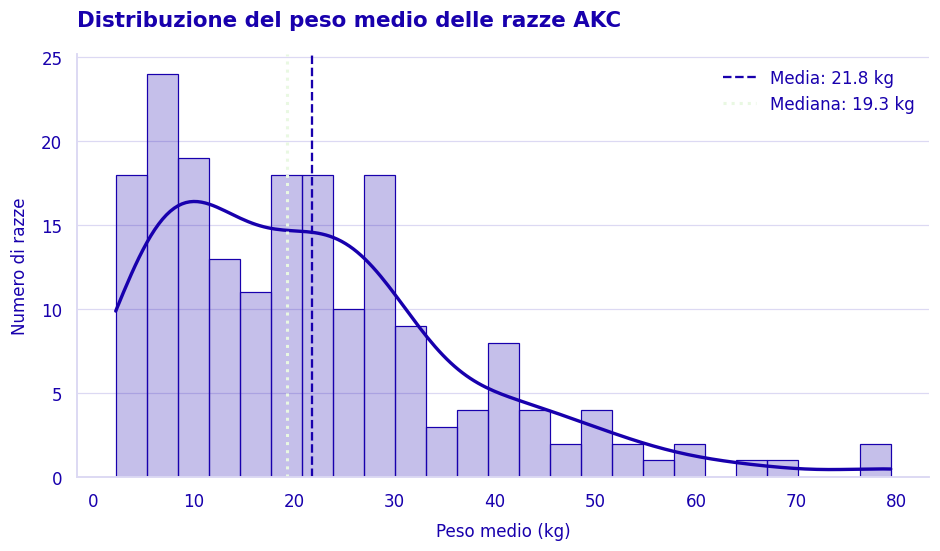

In [6]:
media, mediana = df["avg_weight"].mean(), df["avg_weight"].median()

fig, ax = plt.subplots(figsize=(10, 5))
sns.histplot(data=df, x="avg_weight", bins=25, kde=True, color=PRIMARIO, alpha=0.25,
             edgecolor=PRIMARIO, linewidth=0.8, line_kws={"linewidth": 2.2}, ax=ax)
ax.axvline(media, color=PRIMARIO, linestyle="--", linewidth=1.5, label=f"Media: {media:.1f} kg")
ax.axvline(mediana, color=CHIARO, linestyle=":", linewidth=2, label=f"Mediana: {mediana:.1f} kg")
stile_assi(ax, "y")
ax.set(title="Distribuzione del peso medio delle razze AKC", xlabel="Peso medio (kg)", ylabel="Numero di razze")
ax.legend(loc="upper right")
salva(fig, "01_distribuzione_peso.png")

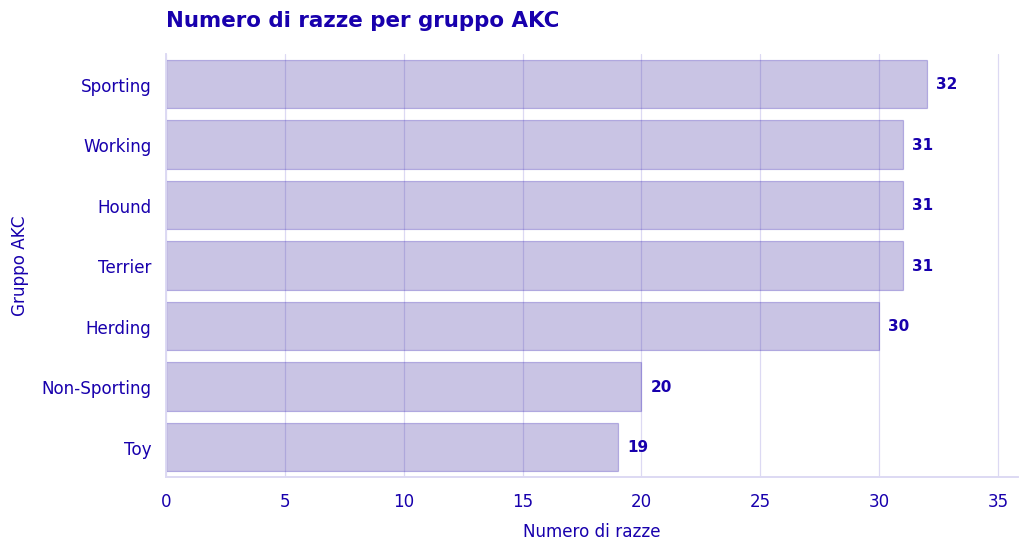

In [7]:
conteggi = df["group"].str.replace(" Group", "").value_counts()

fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(x=conteggi.values, y=conteggi.index, color=PRIMARIO, alpha=0.25,
            edgecolor=PRIMARIO, linewidth=0.8, ax=ax)
ax.bar_label(ax.containers[0], padding=6, fontsize=10, fontweight="bold", color=PRIMARIO)
ax.set_xlim(0, conteggi.max() * 1.12)
stile_assi(ax, "x")
ax.set(title="Numero di razze per gruppo AKC", xlabel="Numero di razze", ylabel="Gruppo AKC")
salva(fig, "02_razze_per_gruppo.png")

## 3. Clustering K-Means sui tratti caratteriali

Feature: 14 | Razze: 194


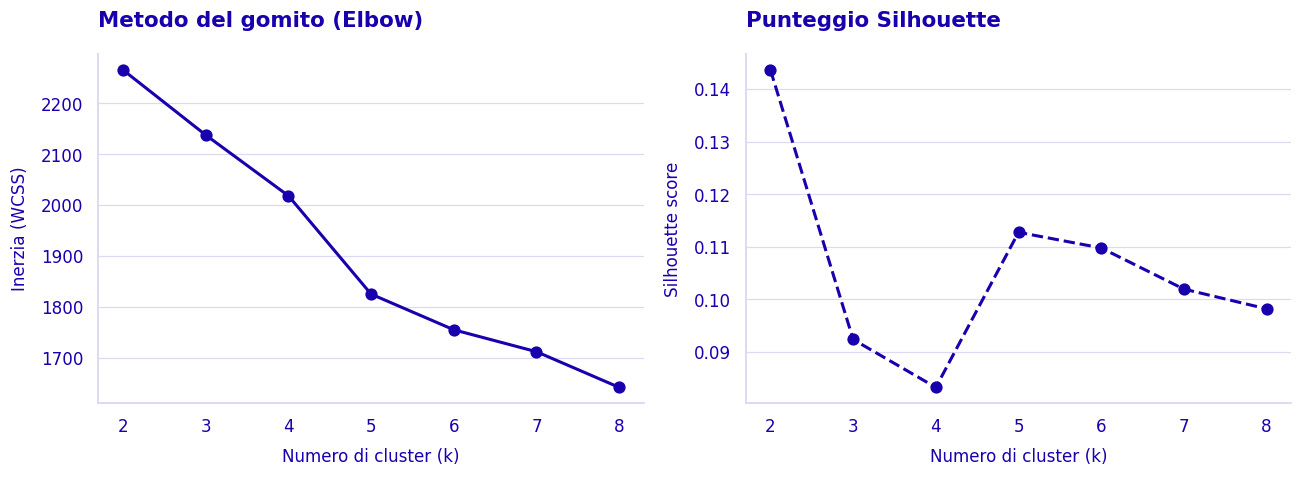

In [8]:
X_scaled = StandardScaler().fit_transform(df[TRATTI])
print(f"Feature: {len(TRATTI)} | Razze: {len(df)}")

k_range = range(2, 9)
inerzia, silhouette = [], []
for k in k_range:
    km = KMeans(n_clusters=k, random_state=42, n_init="auto").fit(X_scaled)
    inerzia.append(km.inertia_)
    silhouette.append(silhouette_score(X_scaled, km.labels_))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, valori, stile, titolo, ylabel in [
    (axes[0], inerzia, "-", "Metodo del gomito (Elbow)", "Inerzia (WCSS)"),
    (axes[1], silhouette, "--", "Punteggio Silhouette", "Silhouette score"),
]:
    ax.plot(list(k_range), valori, stile, marker="o", color=PRIMARIO, linewidth=2, markersize=7)
    ax.set(title=titolo, xlabel="Numero di cluster (k)", ylabel=ylabel, xticks=list(k_range))
    stile_assi(ax, "y")
fig.tight_layout()
salva(fig, "03_gomito_silhouette.png")

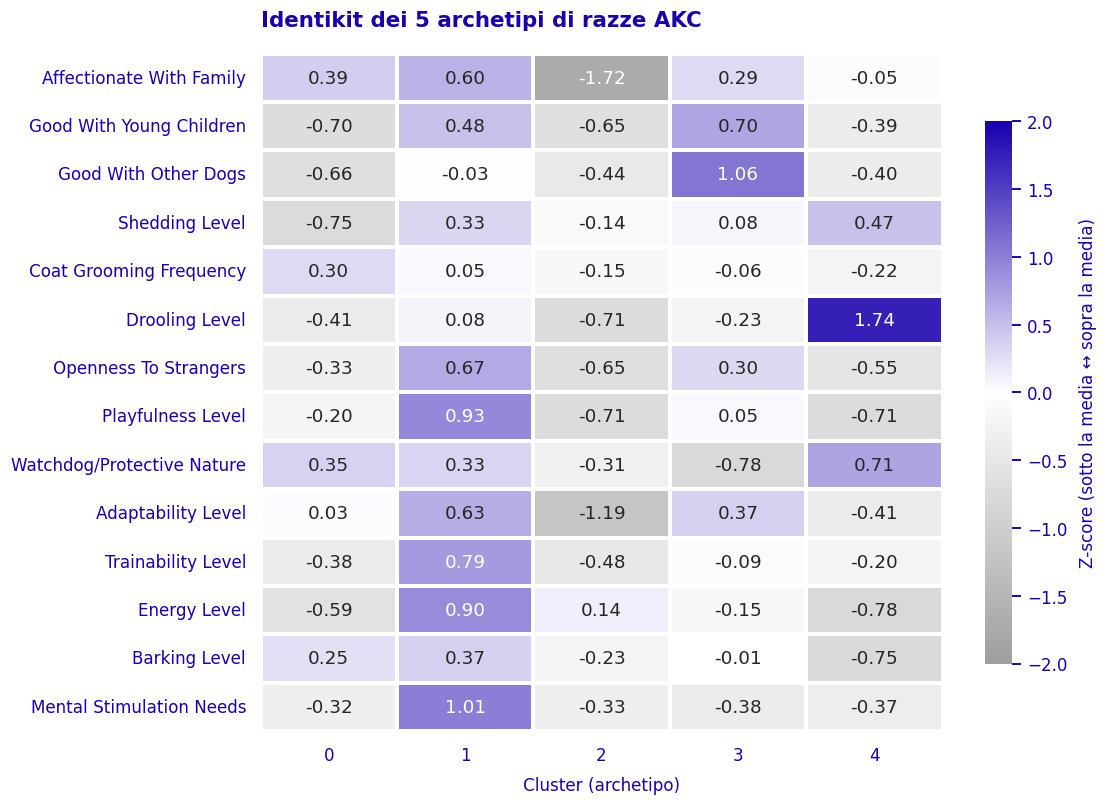

Cluster 0 (37 razze): Dachshunds, Pomeranians, Chihuahuas, Maltese, Shiba Inu, Retrievers (Chesapeake Bay)
Cluster 1 (50 razze): Retrievers (Labrador), German Shepherd Dogs, Poodles, Pointers (German Shorthaired), Pembroke Welsh Corgis, Yorkshire Terriers
Cluster 2 (33 razze): Australian Shepherds, Brittanys, Belgian Malinois, Akitas, Australian Cattle Dogs, Airedale Terriers
Cluster 3 (48 razze): French Bulldogs, Retrievers (Golden), Beagles, Siberian Huskies, Cavalier King Charles Spaniels, Shih Tzu
Cluster 4 (26 razze): Bulldogs, Rottweilers, Great Danes, Cane Corso, Mastiffs, Basset Hounds


In [9]:
# k=5: gomito evidente e massimo locale della silhouette (k=2 separa solo due macro-gruppi)
OPTIMAL_K = 5
df["cluster"] = KMeans(n_clusters=OPTIMAL_K, random_state=42, n_init="auto").fit_predict(X_scaled)
profili = pd.DataFrame(X_scaled, columns=TRATTI).groupby(df["cluster"]).mean()

cmap_div = LinearSegmentedColormap.from_list("neutro_bianco_primario", [NEUTRO, "white", PRIMARIO])

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(profili.T, annot=True, fmt=".2f", cmap=cmap_div, center=0, vmin=-2, vmax=2,
            linewidths=1.5, linecolor="white",
            cbar_kws={"label": "Z-score (sotto la media ↔ sopra la media)", "shrink": 0.8}, ax=ax)
ax.set(title=f"Identikit dei {OPTIMAL_K} archetipi di razze AKC", xlabel="Cluster (archetipo)", ylabel="")
ax.tick_params(axis="y", rotation=0)
cbar = ax.collections[0].colorbar
cbar.ax.yaxis.label.set_color(PRIMARIO)
cbar.ax.tick_params(colors=PRIMARIO)
salva(fig, "04_heatmap_archetipi.png")

for c, gruppo in df.groupby("cluster"):
    print(f"Cluster {c} ({len(gruppo)} razze): {', '.join(gruppo['Breed'].head(6))}")

## 4. Caso studio 1: Beagle reale vs standard AKC

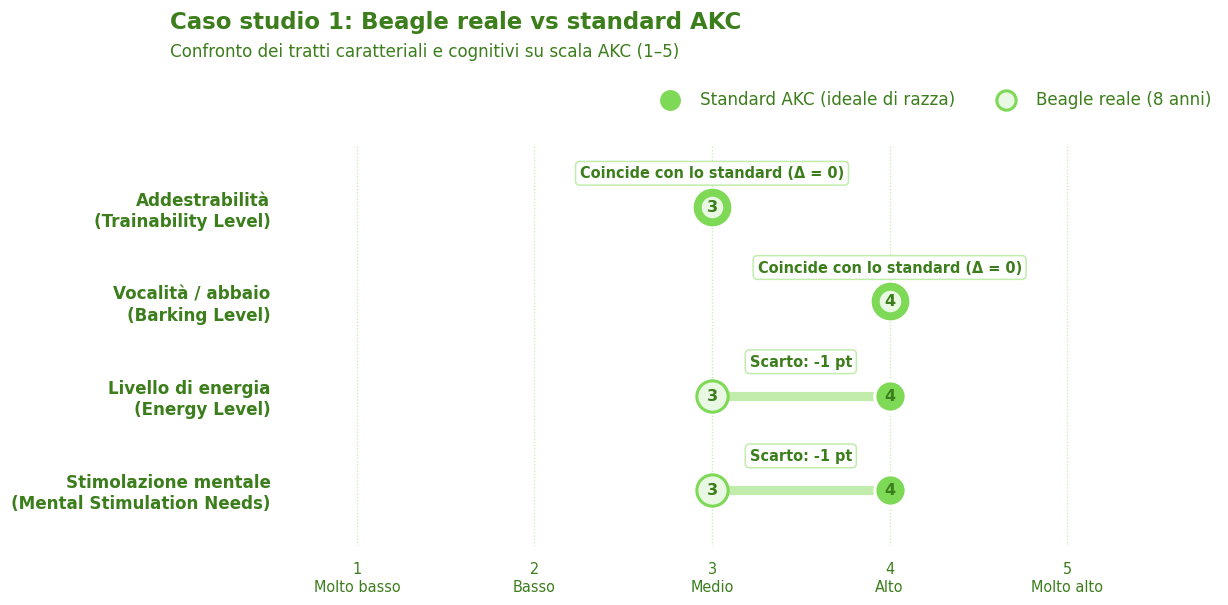

In [11]:
# --- Palette verde (tonalità #7ed957) ---
VERDE  = "#7ed957"   # colore principale: standard AKC
SCURO  = "#3c7d1c"   # stessa tinta, più scura: tutti i testi
CHIARO = "#e9f8e2"   # tinta chiarissima: Beagle reale
TENUE  = "#c1ecac"   # barre di collegamento, griglia, bordi dei box
PRIMARIO = VERDE     # così anche le altre figure del notebook diventano verdi

# --- Tutti i testi in verde (sovrascrive il viola del tema) ---
plt.rcParams.update({
    "text.color": SCURO,
    "axes.labelcolor": SCURO,
    "axes.titlecolor": SCURO,
    "xtick.color": SCURO,
    "ytick.color": SCURO,
    "axes.edgecolor": TENUE,
    "legend.labelcolor": SCURO,
})

TRATTI_BEAGLE = {
    "Mental Stimulation Needs": "Stimolazione mentale",
    "Energy Level": "Livello di energia",
    "Barking Level": "Vocalità / abbaio",
    "Trainability Level": "Addestrabilità",
}
akc_scores = df.loc[df["Breed"] == "Beagles", list(TRATTI_BEAGLE)].iloc[0].to_numpy()
real_scores = np.array([3, 3, 4, 3])   # valutazione del Beagle reale (8 anni), stesso ordine
etichette = [f"{it}\n({en})" for en, it in TRATTI_BEAGLE.items()]
y = np.arange(len(etichette))

fig, ax = plt.subplots(figsize=(10, 5.6))
ax.hlines(y, np.minimum(akc_scores, real_scores), np.maximum(akc_scores, real_scores),
          color=TENUE, linewidth=6, capstyle="round", zorder=1)

def punto(x, yi, colore, testo_colore, s=420, bordo="white"):
    ax.scatter(x, yi, color=colore, s=s, edgecolors=bordo, linewidth=2, zorder=3)
    ax.text(x, yi, str(x), color=testo_colore, ha="center", va="center",
            fontsize=10.5, fontweight="bold", zorder=4)

for yi, akc, real in zip(y, akc_scores, real_scores):
    if akc == real:
        ax.scatter(akc, yi, color=VERDE, s=560, zorder=2)               # anello = standard AKC
        punto(real, yi, CHIARO, SCURO, s=260, bordo=VERDE)              # nucleo = Beagle reale
        nota = "Coincide con lo standard (Δ = 0)"
    else:
        punto(akc, yi, VERDE, SCURO)
        punto(real, yi, CHIARO, SCURO, bordo=VERDE)
        nota = f"Scarto: {real - akc:+d} pt"
    ax.text((akc + real) / 2, yi + 0.28, nota, ha="center", va="bottom", fontsize=9.5,
            fontweight="bold", color=SCURO,
            bbox=dict(boxstyle="round,pad=0.3", facecolor="white", edgecolor=TENUE))

ax.set_yticks(y, etichette, fontsize=11, fontweight="bold", color=SCURO)
ax.set_ylim(-0.6, len(y) - 0.35)
ax.set_xlim(0.6, 5.4)
ax.set_xticks(range(1, 6), ["1\nMolto basso", "2\nBasso", "3\nMedio", "4\nAlto", "5\nMolto alto"],
              fontsize=9.5, color=SCURO)
ax.tick_params(length=0, pad=10, colors=SCURO)
ax.grid(axis="x", linestyle=":", color=TENUE)
ax.set_axisbelow(True)
sns.despine(ax=ax, left=True, bottom=True)

fig.suptitle("Caso studio 1: Beagle reale vs standard AKC", x=0.02, ha="left",
             fontsize=15, fontweight="bold", color=SCURO)
fig.text(0.02, 0.905, "Confronto dei tratti caratteriali e cognitivi su scala AKC (1–5)",
         fontsize=11, color=SCURO)
fig.legend(handles=[plt.scatter([], [], color=VERDE, s=160, label="Standard AKC (ideale di razza)"),
                    plt.scatter([], [], color=CHIARO, edgecolors=VERDE, linewidth=2, s=160,
                                label="Beagle reale (8 anni)")],
           loc="upper right", bbox_to_anchor=(0.98, 0.875), ncol=2, frameon=False,
           labelcolor=SCURO)
fig.subplots_adjust(top=0.76)
salva(fig, "05_beagle_vs_standard.png")

## 5. Caso studio 2: Spacky e la mappa sociale (UMAP)

                            AKC Miniature Pinscher  Spacky  Differenza
Affectionate With Family                         5       5           0
Good With Young Children                         3       5           2
Good With Other Dogs                             4       3          -1
Openness To Strangers                            3       5           2
Watchdog/Protective Nature                       5       4          -1 

                         Razza  Distanza
0                    Papillons       0.0
1                     Samoyeds       0.0
2  Greater Swiss Mountain Dogs       0.0
3                 Rat Terriers       0.0
4                  Leonbergers       0.0
5          Fox Terriers (Wire)       0.0 

Miniature Pinscher AKC: 138° razza più vicina a Spacky su 194
Profili sociali distinti nel dataset: 83 su 194


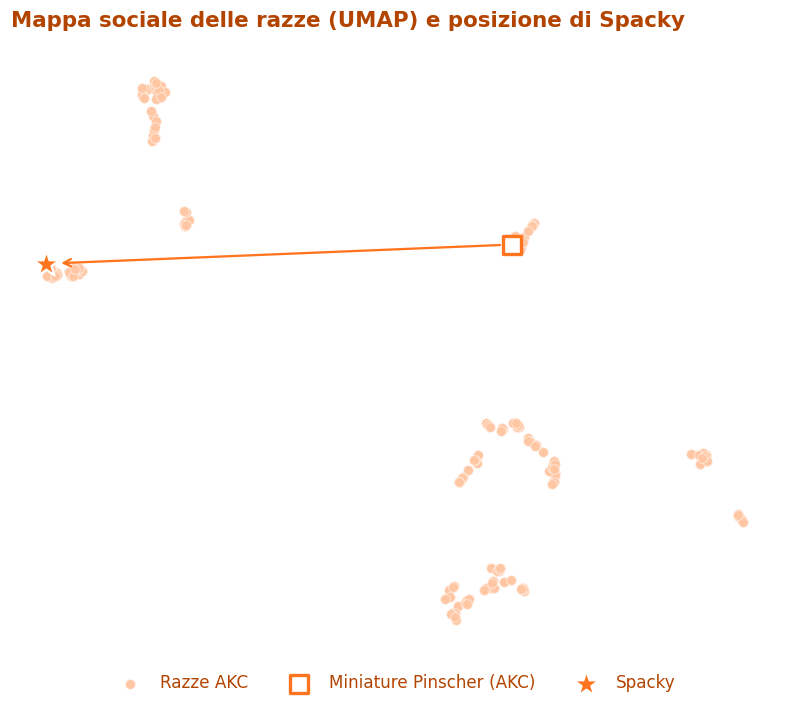

In [12]:
# --- Palette arancione (tonalità #ff751f) ---
ARANCIO        = "#ff751f"   # colore principale: Spacky, Miniature Pinscher, freccia
ARANCIO_SCURO  = "#b34400"   # stessa tinta, più scura: titolo e legenda
ARANCIO_TENUE  = "#ffc6a3"   # punti delle razze AKC
ARANCIO_CHIARO = "#ffece0"   # bordo dei punti delle razze

SOCIALI = ["Affectionate With Family", "Good With Young Children", "Good With Other Dogs",
           "Openness To Strangers", "Watchdog/Protective Nature"]

S = df[SOCIALI]
sc = StandardScaler().fit(S)                         # scaler addestrato solo sulle razze
S_scaled = sc.transform(S)
reducer = umap.UMAP(n_neighbors=15, min_dist=0.1, random_state=42).fit(S_scaled)
emb = reducer.embedding_

mp_idx = df.index[df["Breed"] == "Miniature Pinschers"][0]
spacky = pd.DataFrame([[5, 5, 3, 5, 4]], columns=SOCIALI)   # voti di Spacky, stesso ordine
spacky_scaled = sc.transform(spacky)
spacky_emb = reducer.transform(spacky_scaled)                # proiezione senza riaddestrare

confronto = pd.DataFrame({"AKC Miniature Pinscher": S.loc[mp_idx], "Spacky": spacky.iloc[0]})
confronto["Differenza"] = confronto["Spacky"] - confronto["AKC Miniature Pinscher"]
print(confronto, "\n")

# Vicini nello spazio originale (non in quello UMAP)
d = np.linalg.norm(S_scaled - spacky_scaled, axis=1)
vicini = np.argsort(d, kind="stable")[:6]
print(pd.DataFrame({"Razza": df.loc[vicini, "Breed"].values, "Distanza": d[vicini].round(2)}), "\n")
rango = (d < d[mp_idx]).sum() + 1                    # a pari distanza conta come lo stesso posto
print(f"Miniature Pinscher AKC: {rango}° razza più vicina a Spacky su {len(d)}")
print(f"Profili sociali distinti nel dataset: {S.drop_duplicates().shape[0]} su {len(S)}")

fig, ax = plt.subplots(figsize=(9, 7))
ax.scatter(emb[:, 0], emb[:, 1], color=ARANCIO_TENUE, edgecolors=ARANCIO_CHIARO,
           linewidth=0.5, s=40, label="Razze AKC")
ax.scatter(*emb[mp_idx], facecolors="white", edgecolors=ARANCIO, linewidth=2.2, s=140, marker="s",
           label="Miniature Pinscher (AKC)", zorder=3)
ax.scatter(*spacky_emb[0], color=ARANCIO, edgecolors="white", linewidth=1.5, s=320, marker="*",
           label="Spacky", zorder=4)
ax.annotate("", xy=spacky_emb[0], xytext=emb[mp_idx],
            arrowprops=dict(arrowstyle="->", color=ARANCIO, lw=1.5, shrinkA=8, shrinkB=10))
ax.set_title("Mappa sociale delle razze (UMAP) e posizione di Spacky",
             color=ARANCIO_SCURO, fontweight="bold")
ax.set(xticks=[], yticks=[])
sns.despine(ax=ax, left=True, bottom=True)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.02), ncol=3,
          frameon=False, labelcolor=ARANCIO_SCURO)
salva(fig, "06_umap_spacky.png")

## 6. Caso studio 3: Simba vs Greyhound AKC

Ogni asse è normalizzato 0–1 sull'intervallo dell'intero dataset (peso e altezza: min–max delle razze;
perdita pelo e sbavamento: scala 1–5; lunghezza pelo: Short/Medium/Long),
così le differenze tra i due cani sono in proporzione reale.

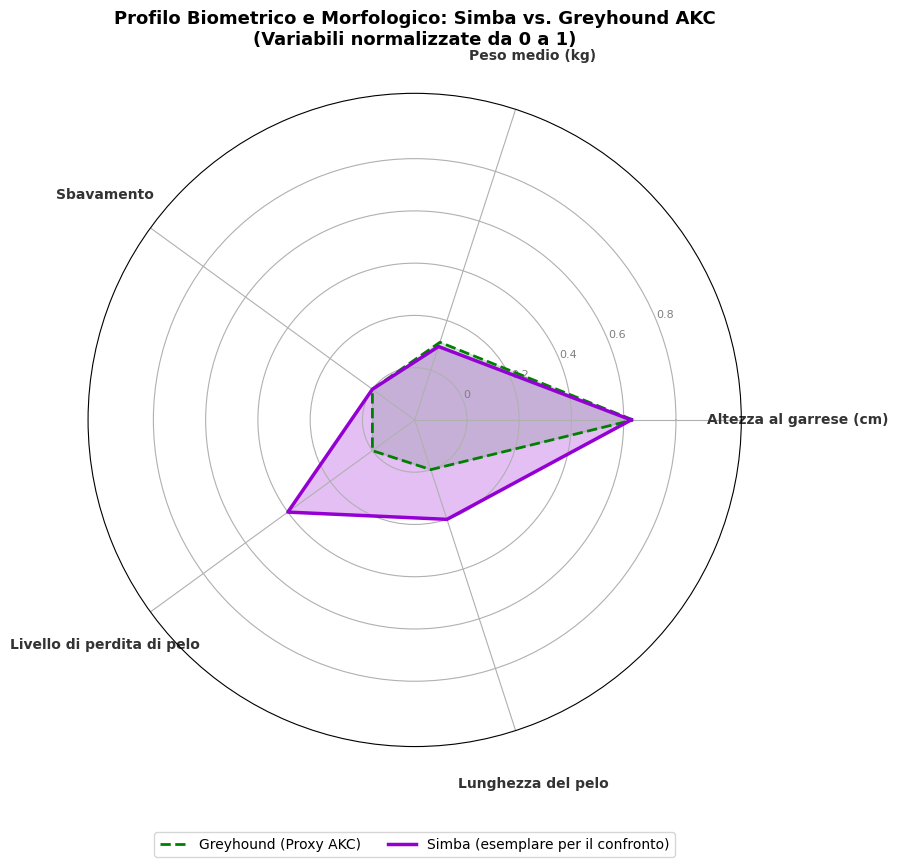

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler

# 1. Definizione delle 5 variabili e dei dati grezzi
features = [
    'Altezza al garrese (cm)',
    'Peso medio (kg)',
    'Sbavamento',
    'Livello di perdita di pelo',
    'Lunghezza del pelo'
]

# Dati di Simba e del Greyhound (Proxy AKC)
simba_raw = [73.0, 28.0, 1.0, 3.0, 2.0]
greyhound_raw = [73.5, 29.5, 1.0, 1.0, 1.0]

# Ancoraggio ai limiti reali delle scale per una normalizzazione 0-1 fedele
scale_bounds = np.array([
    [15.0, 2.0, 0.0, 0.0, 0.0],   # Minimi di scala
    [85.0, 90.0, 5.0, 5.0, 5.0]    # Massimi di scala
])

scaler = MinMaxScaler()
scaler.fit(scale_bounds)

simba_norm = scaler.transform([simba_raw])[0]
greyhound_norm = scaler.transform([greyhound_raw])[0]

# Chiusura del poligono per il Radar Chart
num_vars = len(features)
angles = np.linspace(0, 2 * np.pi, num_vars, endpoint=False).tolist()

simba_plot = np.concatenate((simba_norm, [simba_norm[0]]))
greyhound_plot = np.concatenate((greyhound_norm, [greyhound_norm[0]]))
angles += angles[:1]

# Creazione della figura con margini ottimizzati
fig, ax = plt.subplots(figsize=(9, 9), subplot_kw=dict(polar=True))

# NOTA CHIAVE: Impostiamo il limite a 1.25 e l'origine a 0 per lasciare spazio ai vertici
ax.set_ylim(0, 1.25)
ax.set_rorigin(0)

# Poligono Greyhound (AKC Proxy)
ax.plot(angles, greyhound_plot, linewidth=2, linestyle='--', color='green', label='Greyhound (Proxy AKC)')
ax.fill(angles, greyhound_plot, color='green', alpha=0.15)

# Poligono Simba
ax.plot(angles, simba_plot, linewidth=2.5, linestyle='-', color='darkviolet', label='Simba (esemplare per il confronto)')
ax.fill(angles, simba_plot, color='darkviolet', alpha=0.25)

# Formattazione e spaziatura etichette per evitare sovrapposizioni
ax.set_xticks(angles[:-1])
ax.set_xticklabels(features, fontsize=10, fontweight='bold', color='#333333')
ax.tick_params(axis='x', pad=30)  # Aumentato il padding per distanziare il testo dal bordo

# Griglie radiali (ricalorate fino a 1.0 per la griglia interna)
ax.set_rgrids([0.2, 0.4, 0.6, 0.8, 1.0], labels=['0', '0.2', '0.4', '0.6', '0.8'], color='grey', size=8)

# Titolo ben distanziato in alto
plt.title('Profilo Biometrico e Morfologico: Simba vs. Greyhound AKC\n(Variabili normalizzate da 0 a 1)',
          size=13, fontweight='bold', pad=35)

# Legenda posizionata in basso, perfettamente isolata dal grafico
plt.legend(loc='upper center', bbox_to_anchor=(0.5, -0.12), ncol=2, frameon=True)

plt.tight_layout()
plt.show()